In [35]:
import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import v2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path 

In [36]:
DIR = Path("../data/cases_weather_by_region")

def region_key(path):
    """Normalised region name so 'AMNAT CHAROEN' and 'AMNAT_CHAROEN' match."""
    return path.stem.strip().upper().replace(" ", "_")

files = {region_key(p): p for p in sorted(DIR.glob("*.csv"))}
regions = sorted(files.keys())

In [37]:
# import data 
df_dict = {}

for region, path in files.items():
    df = pd.read_csv(path)
    df.drop(columns=[f"valid_time_w{i}" for i in range(1, 5)], inplace=True)
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    
    # Format to datetime
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)

    df_dict[region] = df

for region, df in df_dict.items():
    print(f"Region: {region}")
    print("DataFrame shape:", df.shape)

Region: AMNAT_CHAROEN
DataFrame shape: (240, 14)
Region: ANG_THONG
DataFrame shape: (360, 14)
Region: BANGKOK
DataFrame shape: (360, 14)
Region: BUNGKAN
DataFrame shape: (144, 14)
Region: BURIRAM
DataFrame shape: (360, 14)
Region: CHACHOENGSAO
DataFrame shape: (360, 14)
Region: CHAINAT
DataFrame shape: (360, 14)
Region: CHAIYAPHUM
DataFrame shape: (360, 14)
Region: CHANTHABURI
DataFrame shape: (360, 14)
Region: CHIANG_MAI
DataFrame shape: (360, 14)
Region: CHIANG_RAI
DataFrame shape: (360, 14)
Region: CHONBURI
DataFrame shape: (360, 14)
Region: CHUMPHON
DataFrame shape: (360, 14)
Region: KALASIN
DataFrame shape: (360, 14)
Region: KAMPAENG_PHET
DataFrame shape: (360, 14)
Region: KANCHANABURI
DataFrame shape: (360, 14)
Region: KHON_KAEN
DataFrame shape: (360, 14)
Region: KRABI
DataFrame shape: (360, 14)
Region: LAMPANG
DataFrame shape: (360, 14)
Region: LAMPHUN
DataFrame shape: (360, 14)
Region: LOEI
DataFrame shape: (360, 14)
Region: LOPBURI
DataFrame shape: (360, 14)
Region: MAE_HONG_S

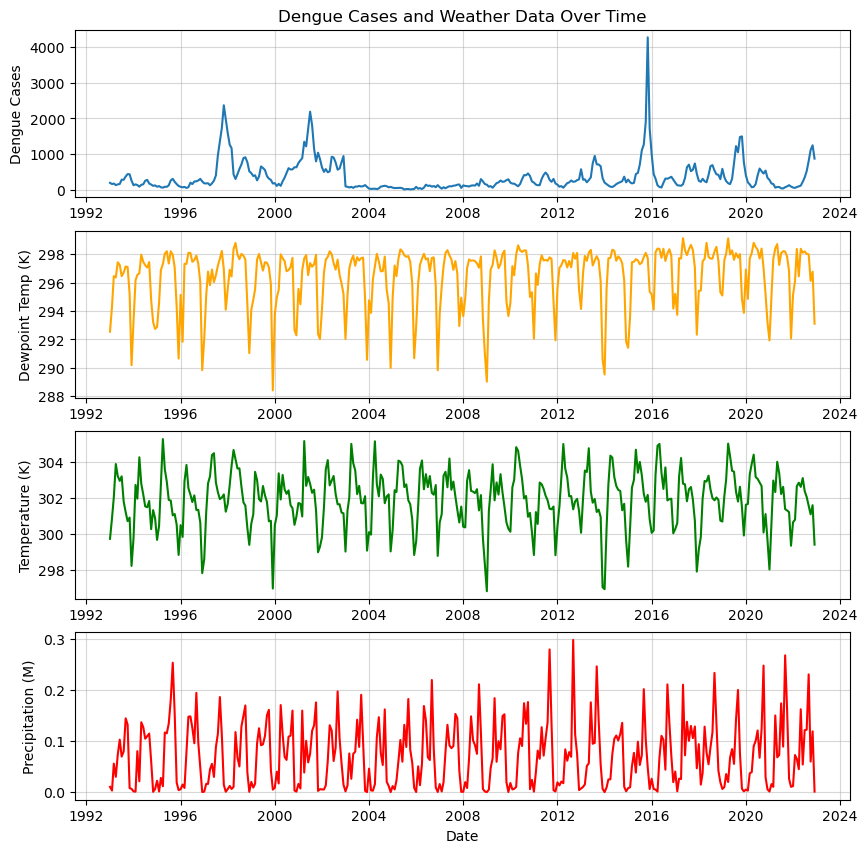

In [38]:
# Plot dengue cases over time along with weather data in Bangkok
df = df_dict["BANGKOK"]

fig, ax = plt.subplots(4, 1, figsize=(10, 10))
ax[0].plot(df["date"], df["dengue_total"],
           label="Total Cases")
ax[1].plot(df["date"], 
           np.mean([df[f"d2m_w{i}"] for i in range(1, 4)], axis=0),
           color="orange",
           label="2m Dewpoint temperature")
ax[2].plot(df["date"], 
           np.mean([df[f"t2m_w{i}"] for i in range(1, 4)], axis=0),
           color="green",
           label="2m Temperature")
ax[3].plot(df["date"], 
           np.sum([df[f"tp_w{i}"] for i in range(1, 4)], axis=0),
           color="red",
           label="Total Precipitation")
ax[3].set_xlabel("Date")
ax[0].set_ylabel("Dengue Cases")
ax[1].set_ylabel("Dewpoint Temp (K)")
ax[2].set_ylabel("Temperature (K)")
ax[3].set_ylabel("Precipitation (M)")
ax[0].set_title("Dengue Cases and Weather Data Over Time")
for a in ax:
    a.grid(True, alpha=0.5)
plt.show()

We will create a custom Pytorch Dataset that generates the appropriate input and target vectors.  For a window beginning at week $t$, we'll observe 24 weeks (6 months) of historical weather data and historical Dengue cases. I.e.
$$
X_t = 
\begin{bmatrix}
    W_{m-5} & D_{m-5} \\
    W_{m-4} & D_{m-4} \\
    \vdots & \vdots \\
    W_{m} & D_{m}
\end{bmatrix}
$$
where $W_t$ represents the weather variables, and $D_t$ represents the historical monthly Dengue count.  The target is 
$$
Y_t = \begin{bmatrix}
    D_{m+1} & \cdots & D_{m+6}
\end{bmatrix}
$$
where $m$ is the month containing the final week of the input window. Note that $X_t$ will be a $6\times 13$ matrix, and $Y_t$ will be in $\mathbb{R}^6$. 

In [39]:
class DengueDataset(Dataset):

    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

    def __repr__(self):
        return f"DengueDataset(X={self.X.shape}, Y={self.Y.shape})" 

In [40]:
X = []
Y = []

window_size = 6
forecast_months = 3
step_size = window_size + forecast_months

weather_cols = [
    col for col in df.columns
    if col not in ["date", "dengue_total"]
]

monthly_cases = (
    df.assign(month=df["date"].dt.to_period("M"))
    .drop_duplicates("month")
    .dropna()
    .set_index("month")["dengue_total"]
    .sort_index()
)

input_cols = weather_cols + ["dengue_total"]
for region, df in df_dict.items():
    for i in range(0, len(df) - window_size + 1, step_size):

        window = df.iloc[i:i+window_size]

        last_month = df["date"].iloc[i + window_size - 1].to_period("M")

        target_periods = pd.period_range(
            start=last_month + 1,
            periods=forecast_months,
            freq="M"
        )

        if not target_periods.isin(monthly_cases.index).all():
            continue

        x = window[input_cols].to_numpy(dtype=np.float32)

        y = monthly_cases.loc[target_periods].to_numpy(dtype=np.float32)

        X.append(x)
        Y.append(y)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

print(X.shape, Y.shape)


(2999, 6, 13) (2999, 3)
